## Assignment 2 :: Word2vec & Semantic Similarity

In [ ]:
#!pip3 install -U gensim --break-system-packages

In [2]:
import gensim, operator
from scipy import spatial
import numpy as np
from gensim.models import KeyedVectors

### Import the word2vec pre-trained model

Download the Google News word2vec binary here:

https://drive.google.com/file/d/0B7XkCwpI5KDYNlNUTTlSS21pQmM/edit?resourcekey=0-wjGZdNAUop6WykTtMip30g

In [7]:
# location of the downloaded binary
filepath = "GoogleNews-vectors-negative300.bin"

In [8]:
model = KeyedVectors.load_word2vec_format(filepath, binary=True)

#### Finding the most similar words

In [9]:
model.most_similar('apple')

[('apples', 0.720359742641449),
 ('pear', 0.6450695991516113),
 ('fruit', 0.6410146951675415),
 ('berry', 0.6302294731140137),
 ('pears', 0.6133962273597717),
 ('strawberry', 0.6058260798454285),
 ('peach', 0.6025872230529785),
 ('potato', 0.5960934162139893),
 ('grape', 0.5935864448547363),
 ('blueberry', 0.5866668224334717)]

In [10]:
model.most_similar('Apple')

[('Apple_AAPL', 0.7456987500190735),
 ('Apple_Nasdaq_AAPL', 0.7300410866737366),
 ('Apple_NASDAQ_AAPL', 0.7175091505050659),
 ('Apple_Computer', 0.7145972847938538),
 ('iPhone', 0.6924266219139099),
 ('Apple_NSDQ_AAPL', 0.6868603229522705),
 ('Steve_Jobs', 0.6758421659469604),
 ('iPad', 0.6580768823623657),
 ('Apple_nasdaq_AAPL', 0.6444969773292542),
 ('AAPL_PriceWatch_Alert', 0.6439753174781799)]

### Similarity using the model

In [11]:
str1 = 'Tesla Analyst Raises Price Target To $500 Ahead Of Q3 Print'
str2 = 'Tesla will gain another 14% as company closes in on 500,000 annual deliveries'
str3 = 'Tesla Raises Price Target Ahead Of third quarter'
str4 = 'Tesla grows with more deliveries'

In [13]:
output = model.n_similarity(str1.split(), str3.split())
print(output, str1, str3)
print()
output = model.n_similarity(str1.split(), str4.split())
print(output, str1, str4)
print()
output = model.n_similarity(str2.split(), str4.split())
print(output, str2, str4)
print()
output = model.n_similarity(str2.split(), str3.split())
print(output, str2, str3)
print()

0.8840271 Tesla Analyst Raises Price Target To $500 Ahead Of Q3 Print Tesla Raises Price Target Ahead Of third quarter

0.34630826 Tesla Analyst Raises Price Target To $500 Ahead Of Q3 Print Tesla grows with more deliveries

0.7057826 Tesla will gain another 14% as company closes in on 500,000 annual deliveries Tesla grows with more deliveries

0.45734453 Tesla will gain another 14% as company closes in on 500,000 annual deliveries Tesla Raises Price Target Ahead Of third quarter



### Rank texts based on similiarly

In [ ]:
documents = [{'text': str1}, {'text': str2}, {'text': str3}, {'text': str4}]

#### calculate the similarity score between the first document and every document in the collection

In [ ]:
for d in documents:
    input1 = documents[0]['text'].split()
    input2 = d['text'].split()
    d['sim'] = model.n_similarity(input1, input2)

In [ ]:
documents

[{'text': 'Tesla Analyst Raises Price Target To $500 Ahead Of Q3 Print',
  'sim': 1.0},
 {'text': 'Tesla will gain another 14% as company closes in on 500,000 annual deliveries',
  'sim': 0.3887565},
 {'text': 'Tesla Raises Price Target Ahead Of third quarter',
  'sim': 0.8840271},
 {'text': 'Tesla grows with more deliveries', 'sim': 0.34630826}]

#### Sorting using the built-in **sorted** function

In [ ]:
documents = sorted(documents, key=lambda d: d['sim'], reverse=True)

In [ ]:
for d in documents:
    print(d['sim'])
    print(d['text'])
    print()

1.0
Tesla Analyst Raises Price Target To $500 Ahead Of Q3 Print

0.8840271
Tesla Raises Price Target Ahead Of third quarter

0.3887565
Tesla will gain another 14% as company closes in on 500,000 annual deliveries

0.34630826
Tesla grows with more deliveries



#### Sorting using Pandas dataframe

In [ ]:
import pandas as pd

In [ ]:
df = pd.DataFrame(documents)
df

,text,sim
0,Tesla Analyst Raises Price Target To $500 Ahea...,1.000000
1,Tesla Raises Price Target Ahead Of third quarter,0.884027
2,Tesla will gain another 14% as company closes ...,0.388757
3,Tesla grows with more deliveries,0.346308


In [ ]:
df = df.sort_values(by='sim', ascending=False)
df

,text,sim
0,Tesla Analyst Raises Price Target To $500 Ahea...,1.000000
1,Tesla Raises Price Target Ahead Of third quarter,0.884027
2,Tesla will gain another 14% as company closes ...,0.388757
3,Tesla grows with more deliveries,0.346308


In [ ]:
for i, row in df.iterrows():
    print(row['sim'])
    print(row['text'])
    print()

1.0
Tesla Analyst Raises Price Target To $500 Ahead Of Q3 Print

0.8840271234512329
Tesla Raises Price Target Ahead Of third quarter

0.38875651359558105
Tesla will gain another 14% as company closes in on 500,000 annual deliveries

0.34630826115608215
Tesla grows with more deliveries



### Word Vector Arithmetics

#### king + women - man

In [ ]:
model.most_similar(positive=['king','woman'], negative=['man'])

[('queen', 0.7118193507194519),
 ('monarch', 0.6189674139022827),
 ('princess', 0.5902431011199951),
 ('crown_prince', 0.5499460697174072),
 ('prince', 0.5377321839332581),
 ('kings', 0.5236844420433044),
 ('Queen_Consort', 0.5235945582389832),
 ('queens', 0.5181134343147278),
 ('sultan', 0.5098593831062317),
 ('monarchy', 0.5087411999702454)]

#### king + she - he

In [ ]:
model.most_similar(positive=['king','she'], negative=['he'])

[('queen', 0.7633836269378662),
 ('princess', 0.6342118382453918),
 ('queens', 0.5744965076446533),
 ('monarch', 0.5577755570411682),
 ('goddess', 0.5278830528259277),
 ('princesses', 0.5202734470367432),
 ('Queen_Consort', 0.513454794883728),
 ('very_pampered_McElhatton', 0.5131746530532837),
 ('empress', 0.5119601488113403),
 ('queendom', 0.5091063380241394)]

#### prince + she - he

In [ ]:
model.most_similar(positive=['prince','she'], negative=['he'])

[('princess', 0.7280078530311584),
 ('queen', 0.6324518918991089),
 ('duchess', 0.6196165084838867),
 ('Princess', 0.593896746635437),
 ('Camilla', 0.5768094062805176),
 ('princesses', 0.5753580331802368),
 ('Mette_Marit', 0.5696825385093689),
 ('Queen_Consort', 0.5684539675712585),
 ('Sophie_Wessex', 0.556969165802002),
 ('Denmark_Prince_Frederik', 0.5564094185829163)]

#### Explicit arithmetics using raw vectors

In [ ]:
princess1 = model['prince'] + model['she'] - model['he']

In [ ]:
princess2 = model['princess']

In [ ]:
1-spatial.distance.cosine(princess1, princess2)

0.7699577749183811

In [ ]:
# When the input to the most_similar are words in the vocabulary, they are typically ignored in the output
# That is why the word "prince" appears at the top for a vector input intended for "princess"

model.most_similar(princess1)

[('prince', 0.8703755736351013),
 ('princess', 0.7699578404426575),
 ('duchess', 0.6563585996627808),
 ('queen', 0.6530499458312988),
 ('monarch', 0.6151294708251953),
 ('princes', 0.6122132539749146),
 ('Queen_Consort', 0.6056370735168457),
 ('Camilla', 0.6052128672599792),
 ('Princess', 0.6043408513069153),
 ('Mette_Marit', 0.5979813933372498)]

#### Explicit arithmetics using normed vectors

Normed vectors are vectors with unit length.

Raw vectors $v$ can be scaled to a normed vector $u$ by dividing by its length: $u=v/|v|$

In [ ]:
prince = model.get_vector('prince', norm=True)
princess = model.get_vector('princess', norm=True)
he = model.get_vector('he', norm=True)
she = model.get_vector('she', norm=True)

In [ ]:
princess2 = (prince - he + she)/3

In [ ]:
model.most_similar(princess2)

[('prince', 0.7374817728996277),
 ('princess', 0.7280079126358032),
 ('queen', 0.6324518918991089),
 ('duchess', 0.6196165084838867),
 ('Princess', 0.593896746635437),
 ('Camilla', 0.5768094062805176),
 ('princesses', 0.5753580331802368),
 ('Mette_Marit', 0.5696825385093689),
 ('Queen_Consort', 0.5684539675712585),
 ('Sophie_Wessex', 0.556969165802002)]

### tSNE to visualize high dimensional word vectors in 2D plot

In [ ]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

#### Gather a set of tokens close to 'king', 'queen', 'he', and 'she' to train a tSNE model

In [ ]:
words = ['king','queen','he','she']

In [ ]:
# Get the top 100 tokens from 'king', 'queen', 'he', and 'she'

king = model.most_similar('king', topn=100)
queen = model.most_similar('queen', topn=100)
he = model.most_similar('he', topn=100)
she = model.most_similar('she', topn=100)

In [ ]:
tokens = king + queen + he + she
tokens = list(set([k for k,s in tokens] + words))

In [ ]:
indexes = [tokens.index(w) for w in words]
indexes

[140, 369, 250, 367]

#### Assemble the word vectors for the selected tokens

In [ ]:
X = model[tokens]
X

array([[ 0.15625   , -0.01623535,  0.29882812, ..., -0.07763672,
         0.0625    , -0.26367188],
       [ 0.04638672, -0.02722168,  0.03393555, ..., -0.03149414,
         0.06201172, -0.0246582 ],
       [ 0.11962891, -0.03100586,  0.09082031, ..., -0.02478027,
         0.11914062,  0.00668335],
       ...,
       [ 0.05932617, -0.10449219, -0.02539062, ..., -0.01544189,
         0.0145874 ,  0.08447266],
       [ 0.10253906,  0.12402344, -0.140625  , ...,  0.04956055,
         0.17480469,  0.21679688],
       [-0.05810547,  0.08300781,  0.171875  , ..., -0.02563477,
         0.15527344,  0.04541016]], dtype=float32)

### tSNE

#### Initialize a tSNE model

In [ ]:
tsne = TSNE(n_components=2, n_iter=10000, init='pca', perplexity=350)

#### Obtained the transformed word vectors X_tsne in 2D

In [ ]:
X_tsne = tsne.fit_transform(X)

/usr/local/lib/python3.12/site-packages/sklearn/manifold/_t_sne.py:1162: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


#### Plotting

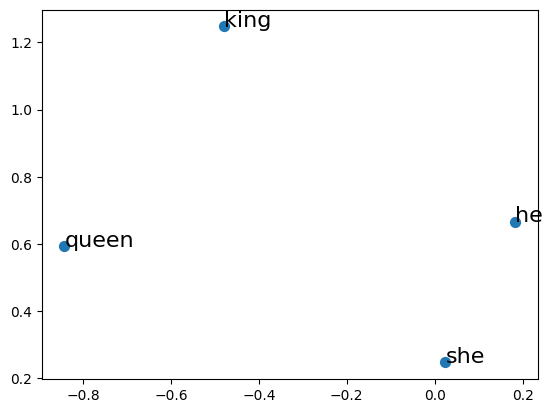

In [ ]:
plt.scatter(X_tsne[indexes, 0], X_tsne[indexes, 1],s=50)
for i in indexes:
    plt.text(X_tsne[i, 0], X_tsne[i, 1], tokens[i], fontsize=16)